In [4]:
import numpy as np
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier

In [5]:
seed = 26006
rng = np.random.default_rng(seed)

In [6]:
faces = fetch_olivetti_faces()
images = faces.images
data = faces.data # feature or X
target = faces.target # output 

In [7]:
# per person shuffle their 10 photos
# 6 to train, 2 to validate and 2 to test

train, validate, test = [], [], []

for person in range(40):
    index = rng.permutation(np.where(target == person)[0])
    train += list(index[:6])
    validate += list(index[6:8])
    test += list(index[8:])

train = np.array(train)
validate = np.array(validate)
test = np.array(test)
# or this way -> 
# train, validate, test = map(np.array, (train, validate, test))



In [8]:
np.savez("slpit.npz", train=train, validate=validate, test=test)

In [9]:
data_train, target_train = data[train], target[train]
data_validate, target_validate = data[validate], target[validate]
data_test, target_test = data[test], target[test]

In [10]:
# part 1 

# establish a single tree baseline 
# max depth is how many questions in a row a tree may ask 
# min sample leaf is the minimum no. of photos allowed in each final box 

In [11]:
depths = [2, 4, 8, 16, None] 
leaves = [1, 2, 4] 

# code tries all 15 combinations, quizzes each one and picks the best 

In [12]:
results = []

for d in depths:
    for m in leaves: 
        clf = DecisionTreeClassifier(max_depth=d, min_samples_leaf=m, random_state=0)
        clf.fit(data_train, target_train)
        results.append((d, m, clf.score(data_train, target_train), clf.score(data_validate, target_validate)))
        # (depth, leaf size, train accuracy, validation accuracy)
        print(d, m, "train=%.3f val=%.3f" % results[-1][2:])

best = max(results, key=lambda r: r[3])
best_d, best_m = best[0], best[1] # depth and leaf size

2 1 train=0.075 val=0.062
2 2 train=0.075 val=0.062
2 4 train=0.075 val=0.062
4 1 train=0.125 val=0.100
4 2 train=0.125 val=0.100
4 4 train=0.125 val=0.100
8 1 train=0.250 val=0.150
8 2 train=0.250 val=0.150
8 4 train=0.250 val=0.150
16 1 train=0.492 val=0.312
16 2 train=0.487 val=0.312
16 4 train=0.483 val=0.312
None 1 train=1.000 val=0.550
None 2 train=0.971 val=0.550
None 4 train=0.963 val=0.550


In [13]:
# this is the baseline tree
tree = DecisionTreeClassifier(max_depth=best_d, min_samples_leaf=best_m, random_state=0).fit(data_train, target_train)

In [14]:
t = tree.tree_
is_leaf = t.children_left == -1
leaf_sizes = t.n_node_samples[is_leaf]

In [15]:
print("train/val/test:", tree.score(data_train, target_train), tree.score(data_validate, target_validate), tree.score(data_test, target_test))

train/val/test: 1.0 0.55 0.6125


In [16]:
print("leaves:", tree.get_n_leaves())
print("mean sample per leaf:", leaf_sizes.mean())
print("fraction of single-example leaves:", (leaf_sizes == 1).mean())

leaves: 49
mean sample per leaf: 4.8979591836734695
fraction of single-example leaves: 0.16326530612244897


In [17]:
'''
what happens as depth increases?

at first the accuracy increases, because a shallow tree underfits even
on the traning data, then as the depth keeps increasing the tree memorizes the training data. 
so training accuracy climbs to 100% but validation/test accuracy flattens. 

number of leaves goes up, mean samples per leaf goes down. 
fraction of single example leaves goes up, meaning more leaves are tiny and holds just one photo. 
'''

'\nwhat happens as depth increases?\n\nat first the accuracy increases, because a shallow tree underfits even\non the traning data, then as the depth keeps increasing the tree memorizes the training data. \nso training accuracy climbs to 100% but validation/test accuracy flattens. \n\nnumber of leaves goes up, mean samples per leaf goes down. \nfraction of single example leaves goes up, meaning more leaves are tiny and holds just one photo. \n'

(b) Implement bagging yourself using bootstrap samples of the original training set size and the frozen tree setting
from part (a). Use B ∈ {1, 5, 10, 25, 50, 100, 200}. For every B, report train, validation and test accuracy and the
average number of distinct examples in one bootstrap sample. Compare the last quantity with its theoretical
expectation.

In [18]:
N = len(data_train) 
B_max = 200  # what does this do? 
n_classes = 40 

rng_bag = np.random.default_rng(seed)

trees = []    # the 200 trained trees
boot_idx = [] # which photos each tree was trained on 

for b in range(B_max):
    idx = rng_bag.integers(0, N, size=N) # 240 draws with replacement
    t = DecisionTreeClassifier(max_depth=best_d, min_samples_leaf=best_m, random_state=b)
    t.fit(data_train[idx], target_train[idx])
    trees.append(t)
    boot_idx.append(idx)

In [19]:
# every tree predicts every photo (once)

pred_train = np.array([t.predict(data_train) for t in trees])
pred_validate = np.array([t.predict(data_validate) for t in trees])
pred_test = np.array([t.predict(data_test) for t in trees])

# Each row is one tree's predictions and each column is one photo. Saving these means we never retrain or repredict later.

In [20]:
# voting function

def vote(preds, B):
    # returns predicted labels and the vote counts 

    n = preds.shape[1]
    counts = np.zeros((n, n_classes), dtype=int) # counts[i, c] = votes for person c on photo i
    for b in range(B):
        counts[np.arange(n), preds[b]] += 1
    return counts.argmax(axis=1), counts

In [21]:
# table for every B 

B_list = [1, 5, 10, 25, 50, 100, 200]

distinct_per_tree = np.array([len(np.unique(i)) for i in boot_idx])
theory = N * (1 - (1 - 1/N)**N)

print("B    train val   test  avg_distinct")
for B in B_list: 
    acc_tr = (vote(pred_train, B)[0] == target_train).mean()
    acc_val = (vote(pred_validate, B)[0] == target_validate).mean()
    acc_test = (vote(pred_test, B)[0] == target_test).mean()
    avg_distinct = distinct_per_tree[:B].mean()
    print(f"{B:<4} {acc_tr:.3f} {acc_val:.3f} {acc_test:.3f} {avg_distinct:.1f}")

print("\ntheoritical expected distinct:", round(theory, 1))

B    train val   test  avg_distinct
1    0.696 0.400 0.400 145.0
5    0.954 0.662 0.700 150.4
10   1.000 0.812 0.738 151.2
25   1.000 0.825 0.812 151.8
50   1.000 0.863 0.850 151.7
100  1.000 0.875 0.863 151.6
200  1.000 0.900 0.850 151.8

theoritical expected distinct: 151.9


(c) For every B, compute out of bag accuracy, average pairwise disagreement between trees, and mean vote margin,
where vote margin is the winning vote fraction minus the runner up vote fraction. Plot all three against B. Select
one final ensemble size using the validation set and explain whether out of bag accuracy, disagreement and vote
margin tell the same story.

In [22]:

import matplotlib.pyplot as plt


In [23]:
oob_accs = []
disagreements = []
vote_margins = []

In [24]:
for B in B_list:
    # Out of Bag Accuracy 
    # evaluted on training samples using only the trees that did not see them 
    oob_correct = 0
    oob_total = 0
    for i in range(N):
        # find indices of trees (up to B) that excluded sample i
        oob_trees = [b for b in range(B) if i not in boot_idx[b]]
        if len(oob_trees) > 0:
            preds_i = [pred_train[b, i] for b in oob_trees]
            # Majority vote among OB trees
            pred_class = np.bincount(preds_i).argmax()
            if pred_class == target_train[i]:
                oob_correct += 1
            oob_total += 1 

    oob_accs.append(oob_correct / oob_total if oob_total > 0 else 0)

    # 2. Average Pairwise Disagreement 
    # Evaluated on the validation set predictions 
    if B == 1:
        disagreements.append(0.0)
    else:
        disagree_sum = 0
        pairs = 0
        for i in range(B):
            for j in range(i + 1, B):
                disagree_sum += np.mean(pred_validate[i] != pred_validate[j])
                pairs += 1
        disagreements.append(disagree_sum / pairs)

    # 3. Mean Vote Margin
    # evaluated on the validation set using vote() function 

    if B == 1:
        vote_margins.append(1.0)
    else:
        _, counts = vote(pred_validate, B)
        # sort counts to easily grab the highest and second-hightest votes
        sorted_counts = np.sort(counts, axis=1)
        winner_votes = sorted_counts[:, -1]
        runner_up_votes = sorted_counts[:, -2]

        margin = (winner_votes - runner_up_votes) / B
        vote_margins.append(margin.mean())

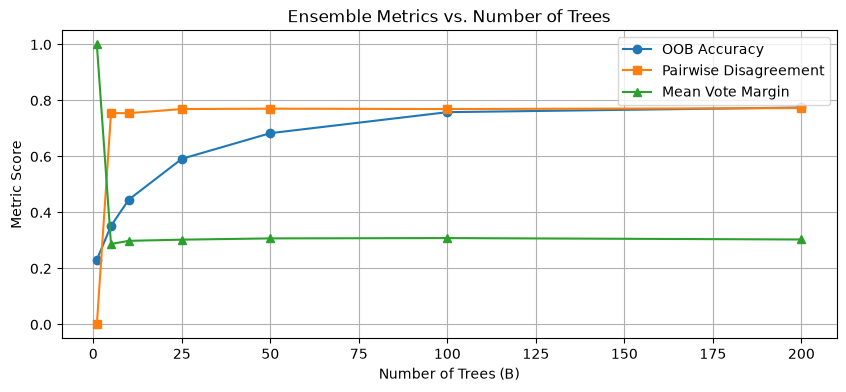

In [25]:
plt.figure(figsize=(10, 4))
plt.plot(B_list, oob_accs, marker='o', label='OOB Accuracy')
plt.plot(B_list, disagreements, marker='s', label='Pairwise Disagreement')
plt.plot(B_list, vote_margins, marker='^', label='Mean Vote Margin')

plt.xlabel('Number of Trees (B)')
plt.ylabel('Metric Score')
plt.title('Ensemble Metrics vs. Number of Trees')
plt.legend()
plt.grid(True)
plt.show()

(d) Compare the frozen single tree and the final bagged model on both the clean and masked test sets. Report
accuracy and prediction confidence for both. Find two faces where bagging corrects the tree and two where both
are wrong. Show the tree prediction and bagging vote counts, and use these cases to explain what type of error
bagging can reduce and what type it cannot.

In [26]:
# create the masked test set 
images_test_masked = data_test.reshape(-1, 64, 64).copy()
images_test_masked[:, 24:40, 24:40] = 0
data_test_masked = images_test_masked.reshape(data_test.shape[0], -1)

# single test evaluation 
tree_pred_clean = tree.predict(data_test)
tree_conf_clean = tree.predict_proba(data_test).max(axis=1).mean()
tree_acc_clean = (tree_pred_clean == target_test).mean()

tree_pred_masked = tree.predict(data_test_masked)
tree_conf_masked = tree.predict_proba(data_test_masked).max(axis=1).mean()
tree_acc_masked = (tree_pred_masked == target_test).mean()

# bagged model evaluation (using B=200 final ensemble)
B_final = 200
pred_test_bag_clean = np.array([t.predict(data_test) for t in trees[:B_final]])
bag_pred_clean, bag_counts_clean = vote(pred_test_bag_clean, B_final)
bag_conf_clean = (bag_counts_clean.max(axis=1) / B_final).mean()
bag_acc_clean = (bag_pred_clean == target_test).mean()

pred_test_bag_masked = np.array([t.predict(data_test_masked) for t in trees[:B_final]])
bag_pred_masked, bag_counts_masked = vote(pred_test_bag_masked, B_final)
bag_conf_masked = (bag_counts_masked.max(axis=1) / B_final).mean()
bag_acc_masked = (bag_pred_masked == target_test).mean()

print(f"Single Tree (Clean)  - Acc: {tree_acc_clean:.3f} | Conf: {tree_conf_clean:.3f}")
print(f"Single Tree (Masked) - Acc: {tree_acc_masked:.3f} | Conf: {tree_conf_masked:.3f}")
print(f"Bagging 200 (Clean)  - Acc: {bag_acc_clean:.3f} | Conf: {bag_conf_clean:.3f}")
print(f"Bagging 200 (Masked) - Acc: {bag_acc_masked:.3f} | Conf: {bag_conf_masked:.3f}\n")

# 4. Find specific facial prediction cases on the clean test set
bag_correct_tree_wrong = np.where((bag_pred_clean == target_test) & (tree_pred_clean != target_test))[0]
both_wrong = np.where((bag_pred_clean != target_test) & (tree_pred_clean != target_test))[0]

print("--- Two faces where bagging corrects the tree ---")
for idx in bag_correct_tree_wrong[:2]:
    true_label = target_test[idx]
    t_pred = tree_pred_clean[idx]
    b_pred = bag_pred_clean[idx]
    b_votes = bag_counts_clean[idx, b_pred]
    print(f"Image Index: {idx} | True Label: {true_label}")
    print(f"  Tree Prediction: {t_pred}")
    print(f"  Bagging Prediction: {b_pred} (Votes: {b_votes}/{B_final})")
    
print("\n--- Two faces where both are wrong ---")
for idx in both_wrong[:2]:
    true_label = target_test[idx]
    t_pred = tree_pred_clean[idx]
    b_pred = bag_pred_clean[idx]
    b_votes = bag_counts_clean[idx, b_pred]
    print(f"Image Index: {idx} | True Label: {true_label}")
    print(f"  Tree Prediction: {t_pred}")
    print(f"  Bagging Prediction: {b_pred} (Votes: {b_votes}/{B_final})")

Single Tree (Clean)  - Acc: 0.613 | Conf: 1.000
Single Tree (Masked) - Acc: 0.375 | Conf: 1.000
Bagging 200 (Clean)  - Acc: 0.850 | Conf: 0.390
Bagging 200 (Masked) - Acc: 0.700 | Conf: 0.264

--- Two faces where bagging corrects the tree ---
Image Index: 0 | True Label: 0
  Tree Prediction: 37
  Bagging Prediction: 0 (Votes: 48/200)
Image Index: 1 | True Label: 0
  Tree Prediction: 16
  Bagging Prediction: 0 (Votes: 60/200)

--- Two faces where both are wrong ---
Image Index: 8 | True Label: 4
  Tree Prediction: 39
  Bagging Prediction: 0 (Votes: 39/200)
Image Index: 17 | True Label: 8
  Tree Prediction: 17
  Bagging Prediction: 29 (Votes: 28/200)
